# Rice variety classification

How well can seven classifiers distinguish Cammeo from Osmancik using grain measurements?

## Load the grain measurements

In [1]:
from scipy.io import arff
import pandas as pd

data, meta = arff.loadarff('Rice_Cammeo_Osmancik.arff')
df = pd.DataFrame(data)

# decode byte strings in the Class column
df['Class'] = df['Class'].str.decode('utf-8')

print(df.shape)
print(df.head())
print(df['Class'].value_counts())

(3810, 8)
      Area   Perimeter  Major_Axis_Length  ...  Convex_Area    Extent   Class
0  15231.0  525.578979         229.749878  ...      15617.0  0.572896  Cammeo
1  14656.0  494.311005         206.020065  ...      15072.0  0.615436  Cammeo
2  14634.0  501.122009         214.106781  ...      14954.0  0.693259  Cammeo
3  13176.0  458.342987         193.337387  ...      13368.0  0.640669  Cammeo
4  14688.0  507.166992         211.743378  ...      15262.0  0.646024  Cammeo

[5 rows x 8 columns]
Class
Osmancik    2180
Cammeo      1630
Name: count, dtype: int64


## Encode the target classes
Convert the categorical class labels into numerical values — Cammeo = 0, Osmancik = 1 — so the models can process the target variable.

In [2]:
df['Class_Label'] = df['Class'].map({'Cammeo': 0, 'Osmancik': 1})

X = df.drop(columns=['Class', 'Class_Label'])
y = df['Class_Label']

print(y.value_counts())
print(df[['Class', 'Class_Label']].head())

Class_Label
1    2180
0    1630
Name: count, dtype: int64
    Class  Class_Label
0  Cammeo            0
1  Cammeo            0
2  Cammeo            0
3  Cammeo            0
4  Cammeo            0


## Split data into training and testing sets
Split the dataset into 80% training data and 20% testing data.
Stratify=y keeps the same proportion of Cammeo and Osmancik in both sets,
since the dataset has a moderate class imbalance. random_state=42 makes
the split reproducible.

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)
print("\nClass proportions in training set:")
print(y_train.value_counts(normalize=True))
print("\nClass proportions in testing set:")
print(y_test.value_counts(normalize=True))

Training set size: (3048, 7)
Testing set size: (762, 7)

Class proportions in training set:
Class_Label
1    0.572178
0    0.427822
Name: proportion, dtype: float64

Class proportions in testing set:
Class_Label
1    0.572178
0    0.427822
Name: proportion, dtype: float64


## Feature standardisation
Some features have much larger values than others.
Standardisation helps the models compare the features more fairly.
The scaler is fitted only on the training data so that the test data
does not influence the model before evaluation.

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Test data shape:", X_test_scaled.shape)
print("\nMean values after scaling:")
print(X_train_scaled.mean(axis=0))
print("\nStandard deviation after scaling:")
print(X_train_scaled.std(axis=0))

Training data shape: (3048, 7)
Test data shape: (762, 7)

Mean values after scaling:
[2.91397119e-16 4.06207584e-16 4.72646128e-16 7.28492798e-16
 2.62840202e-16 1.45698560e-16 6.27086601e-16]

Standard deviation after scaling:
[1. 1. 1. 1. 1. 1. 1.]


## Train all seven models on unscaled data (Round 1)

Train Logistic Regression, KNN, Decision Tree, Random Forest, SVM, Gaussian Naive Bayes and LDA using the original, unscaled training data. This forms Round 1 of the comparison.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

def make_models():
    return {
        "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
        "KNN": KNeighborsClassifier(),
        "Decision Tree": DecisionTreeClassifier(random_state=42),
        "Random Forest": RandomForestClassifier(random_state=42),
        "SVM": SVC(probability=True, random_state=42),
        "Gaussian Naive Bayes": GaussianNB(),
        "LDA": LinearDiscriminantAnalysis(),
    }

models_r1 = make_models()
for name, model in models_r1.items():
    model.fit(X_train, y_train)

print("Round 1: all seven models trained on unscaled data.")

Round 1: all seven models trained on unscaled data.


## Train all seven models on scaled data (Round 2)

Train the same seven models again, this time using the StandardScaler-transformed training data. This forms Round 2 of the comparison, so the effect of feature scaling can be measured for every model, not just some of them.

In [6]:
models_r2 = make_models()
for name, model in models_r2.items():
    model.fit(X_train_scaled, y_train)

print("Round 2: all seven models trained on scaled data.")

Round 2: all seven models trained on scaled data.


## Evaluate Both Rounds on the Test Set

Calculate accuracy, macro precision, macro recall, macro F1-score and ROC-AUC for every model in both rounds using the same test set to ensure a fair and consistent comparison.

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def evaluate_round(models_dict, X_test_data, y_test):
    results = []
    predictions = {}
    for name, model in models_dict.items():
        y_pred = model.predict(X_test_data)
        y_proba = model.predict_proba(X_test_data)[:, 1]
        results.append({
            "Model": name,
            "Accuracy": round(accuracy_score(y_test, y_pred), 4),
            "Macro Precision": round(precision_score(y_test, y_pred, average='macro'), 4),
            "Macro Recall": round(recall_score(y_test, y_pred, average='macro'), 4),
            "Macro F1-Score": round(f1_score(y_test, y_pred, average='macro'), 4),
            "ROC-AUC": round(roc_auc_score(y_test, y_proba), 4)
        })
        predictions[name] = y_pred
    return pd.DataFrame(results), predictions

table_r1, preds_r1 = evaluate_round(models_r1, X_test, y_test)
table_r2, preds_r2 = evaluate_round(models_r2, X_test_scaled, y_test)

table_r1 = table_r1.sort_values(by="Macro F1-Score", ascending=False).reset_index(drop=True)
table_r2 = table_r2.sort_values(by="Macro F1-Score", ascending=False).reset_index(drop=True)

print("Round 1 (unscaled):")
print(table_r1)
print("\nRound 2 (scaled):")
print(table_r2)

Round 1 (unscaled):
                  Model  Accuracy  ...  Macro F1-Score  ROC-AUC
0   Logistic Regression    0.9199  ...          0.9176   0.9760
1                   LDA    0.9147  ...          0.9119   0.9759
2         Random Forest    0.9134  ...          0.9109   0.9702
3         Decision Tree    0.8976  ...          0.8953   0.8947
4  Gaussian Naive Bayes    0.8911  ...          0.8877   0.9585
5                   SVM    0.8688  ...          0.8632   0.9282
6                   KNN    0.8648  ...          0.8599   0.9117

[7 rows x 6 columns]

Round 2 (scaled):
                  Model  Accuracy  ...  Macro F1-Score  ROC-AUC
0   Logistic Regression    0.9160  ...          0.9138   0.9750
1                   LDA    0.9147  ...          0.9119   0.9759
2         Random Forest    0.9134  ...          0.9109   0.9702
3                   SVM    0.9108  ...          0.9083   0.9562
4                   KNN    0.9094  ...          0.9072   0.9490
5         Decision Tree    0.8976  ...     

## Compare Round 1 and Round 2

Build a comparison table showing the accuracy of each model before and after standardisation. This allows the effect of StandardScaler to be measured and shows which models improved, remained unchanged or performed slightly worse after scaling.

In [8]:
comparison = pd.DataFrame({
    "Model": table_r1["Model"],
    "Accuracy (R1)": table_r1["Accuracy"],
    "Accuracy (R2)": table_r2.set_index("Model").loc[table_r1["Model"], "Accuracy"].values,
})
comparison["Difference"] = round(comparison["Accuracy (R2)"] - comparison["Accuracy (R1)"], 4)
print(comparison)

                  Model  Accuracy (R1)  Accuracy (R2)  Difference
0   Logistic Regression         0.9199         0.9160     -0.0039
1                   LDA         0.9147         0.9147      0.0000
2         Random Forest         0.9134         0.9134      0.0000
3         Decision Tree         0.8976         0.8976      0.0000
4  Gaussian Naive Bayes         0.8911         0.8950      0.0039
5                   SVM         0.8688         0.9108      0.0420
6                   KNN         0.8648         0.9094      0.0446


Visualising the comparison from Step 8 as a bar chart, to show the accuracy difference between Round 1 and Round 2 for each model more clearly.

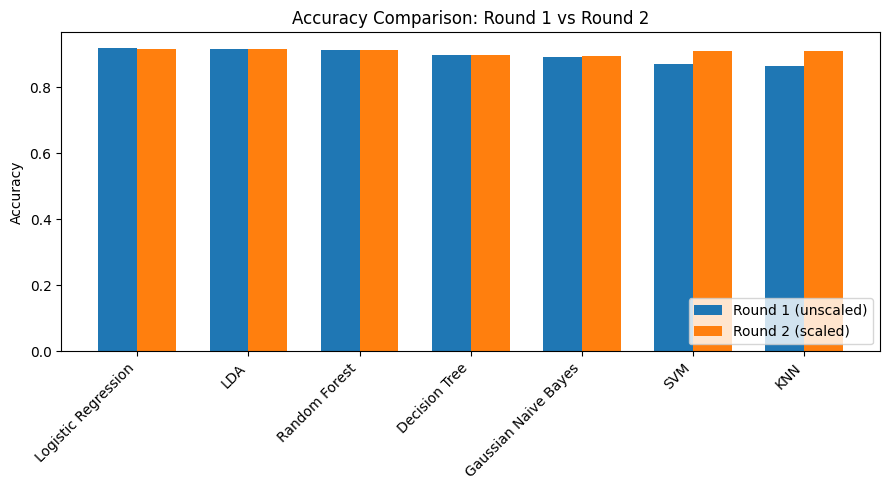

In [9]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(comparison))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width/2, comparison["Accuracy (R1)"], width, label="Round 1 (unscaled)")
plt.bar(x + width/2, comparison["Accuracy (R2)"], width, label="Round 2 (scaled)")
plt.xticks(x, comparison["Model"], rotation=45, ha='right')
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison: Round 1 vs Round 2")
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Identify the Two Lowest-Performing Models in Round 2

Sort the Round 2 results by macro F1-score to identify the two weakest models after standardisation. These models will be analysed further using feature selection in the next section.

In [10]:
two_lowest_r2 = table_r2.sort_values(by="Macro F1-Score").head(2)
print("Two lowest-performing models in Round 2:")
print(two_lowest_r2)

Two lowest-performing models in Round 2:
                  Model  Accuracy  ...  Macro F1-Score  ROC-AUC
6  Gaussian Naive Bayes    0.8950  ...          0.8919   0.9674
5         Decision Tree    0.8976  ...          0.8953   0.8947

[2 rows x 6 columns]


## Correlations in the training set

Look for redundant measurements. Gaussian Naive Bayes assumes conditional independence within each class. A strong overall correlation motivates a feature-removal experiment.

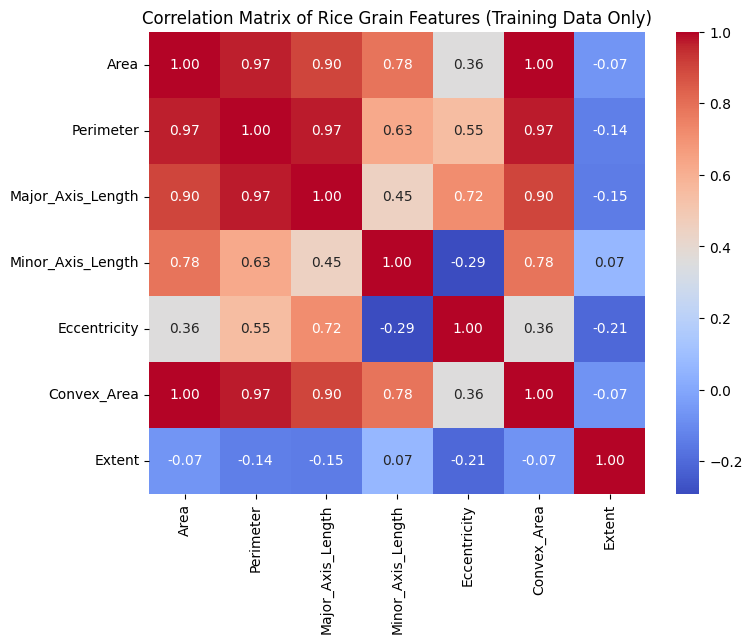

                       Area  Perimeter  ...  Convex_Area    Extent
Area               1.000000   0.966724  ...     0.998931 -0.065220
Perimeter          0.966724   1.000000  ...     0.970114 -0.136081
Major_Axis_Length  0.903057   0.971962  ...     0.903332 -0.145650
Minor_Axis_Length  0.783550   0.625006  ...     0.783173  0.065262
Eccentricity       0.359039   0.550207  ...     0.359419 -0.207337
Convex_Area        0.998931   0.970114  ...     1.000000 -0.069901
Extent            -0.065220  -0.136081  ...    -0.069901  1.000000

[7 rows x 7 columns]


In [11]:
import seaborn as sns

correlation_matrix = X_train.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix of Rice Grain Features (Training Data Only)')
plt.show()

print(correlation_matrix)

## Remove the Highly Correlated Convex Area Feature

Area and Convex Area are almost perfectly correlated (0.9989), indicating that they contain highly similar information. Therefore, Convex Area is removed to reduce feature redundancy. The reduced dataset is then split and standardised again using the same train–test split and StandardScaler settings as before, ensuring that both lowest-performing models are retrained and evaluated under consistent experimental conditions.

In [12]:
X_reduced = X.drop(columns=['Convex_Area'])

X_train_reduced, X_test_reduced, y_train, y_test = train_test_split(
    X_reduced, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler_reduced = StandardScaler()
X_train_reduced_scaled = scaler_reduced.fit_transform(X_train_reduced)
X_test_reduced_scaled = scaler_reduced.transform(X_test_reduced)

print("Reduced training set shape:", X_train_reduced.shape)
print("Reduced testing set shape:", X_test_reduced.shape)
print("Remaining features:", list(X_reduced.columns))

Reduced training set shape: (3048, 6)
Reduced testing set shape: (762, 6)
Remaining features: ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Extent']


## Retrain Gaussian Naive Bayes and Decision Tree Without Convex Area

Retrain the two lowest-performing models from Round 2 using the reduced and standardised feature set. Predictions are then generated on the corresponding test set to compare their performance with the original Round 2 results.

In [13]:
naive_bayes_modified = GaussianNB()
naive_bayes_modified.fit(X_train_reduced_scaled, y_train)
y_pred_nb_modified = naive_bayes_modified.predict(X_test_reduced_scaled)
y_proba_nb_modified = naive_bayes_modified.predict_proba(X_test_reduced_scaled)[:, 1]

dec_tree_modified = DecisionTreeClassifier(random_state=42)
dec_tree_modified.fit(X_train_reduced_scaled, y_train)
y_pred_dt_modified = dec_tree_modified.predict(X_test_reduced_scaled)
y_proba_dt_modified = dec_tree_modified.predict_proba(X_test_reduced_scaled)[:, 1]

print("Both models retrained on the reduced feature set.")

Both models retrained on the reduced feature set.


## Benchmark Both Models Before and After Feature Selection

Calculate accuracy, macro precision, macro recall, macro F1-score and ROC-AUC for both models before feature selection using the Round 2 results with all seven features, and after feature selection using the reduced feature set. This comparison shows whether removing the highly correlated Convex Area feature improved the performance of each model.

In [14]:
def get_metrics(y_true, y_pred, y_proba):
    return {
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "Macro Precision": round(precision_score(y_true, y_pred, average='macro'), 4),
        "Macro Recall": round(recall_score(y_true, y_pred, average='macro'), 4),
        "Macro F1-Score": round(f1_score(y_true, y_pred, average='macro'), 4),
        "ROC-AUC": round(roc_auc_score(y_true, y_proba), 4)
    }

nb_before = get_metrics(y_test, preds_r2["Gaussian Naive Bayes"],
                         models_r2["Gaussian Naive Bayes"].predict_proba(X_test_scaled)[:, 1])
nb_after = get_metrics(y_test, y_pred_nb_modified, y_proba_nb_modified)

dt_before = get_metrics(y_test, preds_r2["Decision Tree"],
                         models_r2["Decision Tree"].predict_proba(X_test_scaled)[:, 1])
dt_after = get_metrics(y_test, y_pred_dt_modified, y_proba_dt_modified)

benchmark = pd.DataFrame({
    "Metric": list(nb_before.keys()),
    "Naive Bayes (Before)": list(nb_before.values()),
    "Naive Bayes (After)": list(nb_after.values()),
    "Decision Tree (Before)": list(dt_before.values()),
    "Decision Tree (After)": list(dt_after.values()),
})

print(benchmark)

            Metric  ...  Decision Tree (After)
0         Accuracy  ...                 0.8924
1  Macro Precision  ...                 0.8906
2     Macro Recall  ...                 0.8893
3   Macro F1-Score  ...                 0.8899
4          ROC-AUC  ...                 0.8893

[5 rows x 5 columns]


## Confusion Matrices for Both Models Before Feature Selection

Create confusion matrices for the original Round 2 versions of Gaussian Naive Bayes and Decision Tree (with all seven features), before Convex Area is removed, for comparison with the modified models below.

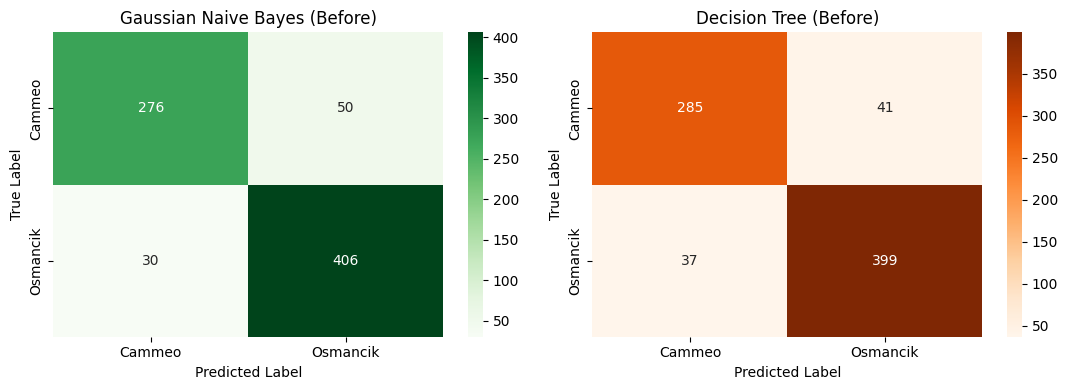

Gaussian Naive Bayes (Before):
[[276  50]
 [ 30 406]]

Decision Tree (Before):
[[285  41]
 [ 37 399]]


In [15]:
from sklearn.metrics import confusion_matrix

cm_nb_before = confusion_matrix(y_test, preds_r2["Gaussian Naive Bayes"])
cm_dt_before = confusion_matrix(y_test, preds_r2["Decision Tree"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.heatmap(cm_nb_before, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Cammeo', 'Osmancik'],
            yticklabels=['Cammeo', 'Osmancik'], ax=axes[0])
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')
axes[0].set_title('Gaussian Naive Bayes (Before)')

sns.heatmap(cm_dt_before, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Cammeo', 'Osmancik'],
            yticklabels=['Cammeo', 'Osmancik'], ax=axes[1])
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')
axes[1].set_title('Decision Tree (Before)')

plt.tight_layout()
plt.show()

print("Gaussian Naive Bayes (Before):")
print(cm_nb_before)
print("\nDecision Tree (Before):")
print(cm_dt_before)

## Confusion Matrices for Both Models After Feature Selection

Create confusion matrices for the modified Gaussian Naive Bayes and Decision Tree models after feature selection. Compare the number and type of classification errors with their original Round 2 versions to determine how removing the highly correlated Convex Area feature affected each model.

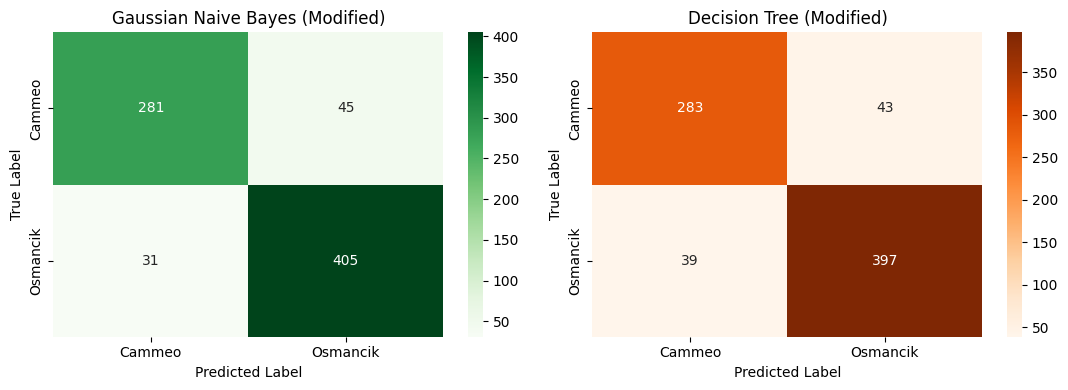

Gaussian Naive Bayes (Modified):
[[281  45]
 [ 31 405]]

Decision Tree (Modified):
[[283  43]
 [ 39 397]]


In [16]:
from sklearn.metrics import confusion_matrix

cm_nb_modified = confusion_matrix(y_test, y_pred_nb_modified)
cm_dt_modified = confusion_matrix(y_test, y_pred_dt_modified)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.heatmap(cm_nb_modified, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Cammeo', 'Osmancik'],
            yticklabels=['Cammeo', 'Osmancik'], ax=axes[0])
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')
axes[0].set_title('Gaussian Naive Bayes (Modified)')

sns.heatmap(cm_dt_modified, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Cammeo', 'Osmancik'],
            yticklabels=['Cammeo', 'Osmancik'], ax=axes[1])
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')
axes[1].set_title('Decision Tree (Modified)')

plt.tight_layout()
plt.show()

print("Gaussian Naive Bayes (Modified):")
print(cm_nb_modified)
print("\nDecision Tree (Modified):")
print(cm_dt_modified)

## Interpret the Results

Compare the performance of Gaussian Naive Bayes and Decision Tree before and after feature selection. Explain why removing the highly correlated Convex Area feature improved one model but slightly reduced the performance of the other, considering how each algorithm uses correlated features.

Removing Convex_Area reduced Gaussian Naive Bayes errors from 80 to 76 and increased Decision Tree errors from 78 to 82 on the same 762 grains. Redundant measurements may affect how Naive Bayes combines evidence, while a tree can use either measurement for a split. These are possible explanations for the observed differences.